# Topic Modeling: Public Reaction to AI-Related Short-Form Video Content
**Data:** YouTube and TikTok comments | **Models:** LDA (gensim) and BERTopic | **Metrics:** c_v, u_mass, held-out perplexity, topic diversity

Pipeline: load, filter, preprocess, explore, 90/10 split, LDA (choose k by coherence), evaluate, visualize, BERTopic, compare, topic-by-platform.

In [ ]:
!pip install -q gensim pyLDAvis bertopic sentence-transformers umap-learn hdbscan langdetect
# Running locally on Python 3.14? gensim has no 3.14 wheel yet, so install it from git instead:
# !pip install git+https://github.com/RaRe-Technologies/gensim.git

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 15.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 38.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 33.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.7/154.7 kB 6.6 MB/s eta 0:00:00


## 1. Imports and settings

In [ ]:
import json, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from langdetect import detect, DetectorFactory
from sklearn.model_selection import train_test_split
from gensim.corpora import Dictionary
from gensim.models import LdaModel, CoherenceModel
from gensim.models.phrases import Phrases

warnings.filterwarnings("ignore")
SEED = 42
DetectorFactory.seed = SEED
DATA_PATH = "preprocessed_dataset.json"
MAX_PER_VIDEO = 100      # cap so no single video dominates the topics
MIN_TOKENS = 3           # minimum tokens per comment after cleaning

## 2. Load data

In [ ]:
try:
    from google.colab import files
    IN_COLAB = True
    import os
    if not os.path.exists(DATA_PATH):
        files.upload()          # choose preprocessed_dataset.json
except ImportError:
    IN_COLAB = False

with open(DATA_PATH, encoding="utf-8") as f:
    raw = json.load(f)
df = pd.DataFrame(raw["documents"])
print("Loaded:", df.shape)
print(df["platform"].value_counts())
df[["platform", "original_text", "clean_text"]].head()

Loaded: (6554, 14)
platform
TikTok     5522
YouTube    1032
Name: count, dtype: int64


,platform,original_text,clean_text
0,YouTube,Finaly a straight to the point shortfilm. No d...,finaly straight point shortfilm dragged dialogues
1,YouTube,For real I hate that shit lol,real hate shit lol
2,YouTube,I conquer,conquer
3,YouTube,Aw he loved her before she lost weight,loved lost weight
4,YouTube,Am just loving the wife and also how she prote...,loving wife also protect kids like also treate...


## 3. Filtering
Steps: drop duplicate comments, drop very short comments, keep English/Tagalog only (the TikTok data contains a lot of Italian), cap comments per video.

In [ ]:
n0 = len(df)
df = df.drop_duplicates("clean_text")
df = df[df["clean_text"].str.split().str.len() >= MIN_TOKENS]
n1 = len(df)

def lang(t):
    try:
        return detect(t)
    except Exception:
        return "unk"

df["lang"] = df["original_text"].apply(lang)
print(df["lang"].value_counts().head(8))
df = df[df["lang"].isin(["en", "tl"])]
n2 = len(df)

df = (df.sample(frac=1, random_state=SEED)            # shuffle, then keep up to N per video
        .groupby("content_id").head(MAX_PER_VIDEO)
        .reset_index(drop=True))
n3 = len(df)

pd.DataFrame({"step": ["start", "dedupe + min tokens", "English/Tagalog only", "cap per video"],
              "rows": [n0, n1, n2, n3]})

lang
en    1633
it    1132
id      60
da      51
fr      49
tl      44
pt      33
so      33
Name: count, dtype: int64


,step,rows
0,start,6554
1,dedupe + min tokens,3302
2,English/Tagalog only,1677
3,cap per video,1357


## 4. Preprocessing for topic modeling
Here we remove domain stopwords (filler such as "next part please") and tokenize.

In [ ]:
STOP = {
    # AI terms that appear everywhere
    "ai", "artificial", "intelligence", "chatgpt", "gpt",
    # platform and request filler
    "next", "part", "episode", "please", "pls", "plz", "movie", "channel", "subscribe",
    "thank", "thanks", "watch", "watching", "watched", "full", "drama", "video", "videos",
    "like", "just", "really", "one", "get", "can", "don", "will", "now", "make", "made",
    # common Taglish fillers
    "ang", "ng", "na", "sa", "mga", "po", "ako", "ka", "ko", "naman", "lang", "yung",
    "din", "ba", "pa", "kasi", "talaga",
    # emoji names, platform names and Pidgin fillers seen in the data
    "red", "heart", "joy", "face", "tiktok", "instagram", "facebook", "youtube",
    "https", "www", "dey", "abeg", "yae",
}

def tokenize(text):
    return [w for w in re.findall(r"[a-z']+", text.lower()) if w not in STOP and len(w) > 2]

df["tokens"] = df["clean_text"].apply(tokenize)
df = df[df["tokens"].str.len() >= 2].reset_index(drop=True)
print("Rows after stopword removal:", len(df))
df[["clean_text", "tokens"]].head()

Rows after stopword removal: 1288


,clean_text,tokens
0,even laughing anymore tears montoya por favor,"[even, laughing, anymore, tears, montoya, por,..."
1,blonde chick always shouting mean parents,"[blonde, chick, always, shouting, mean, parents]"
2,gods mortal want,"[gods, mortal, want]"
3,thank drama please post rest,"[post, rest]"
4,love temper heartwarming,"[love, temper, heartwarming]"


## 5. Data exploration

           count  mean  std  min  25%  50%  75%    max
platform                                              
TikTok    1002.0   5.1  4.0  2.0  3.0  4.0  6.0   57.0
YouTube    286.0   6.7  9.1  2.0  3.0  4.0  7.0  126.0

Comments per video (top 5):
content_id
7482999322599181614    99
n9D3b0K9pko            96
7469458353190636805    92
7686339862995291422    87
7676528108995972374    82
dtype: int64


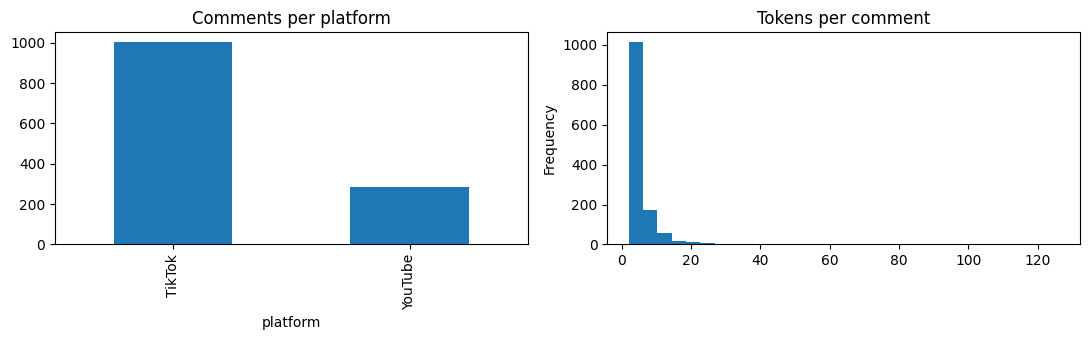

TikTok [('back', 54), ('love', 52), ('man', 45), ('bring', 39), ('story', 37), ('know', 36), ('people', 34), ('want', 31), ('see', 29), ('girl', 27), ('even', 26), ('tears', 26), ('good', 25), ('someone', 25), ('always', 25)]
YouTube [('even', 25), ('love', 23), ('story', 21), ('good', 20), ('god', 14), ('lol', 13), ('much', 12), ('interesting', 12), ('rest', 11), ('time', 10), ('well', 10), ('every', 9), ('way', 9), ('people', 9), ('loved', 9)]


In [ ]:
df["n_tokens"] = df["tokens"].str.len()
print(df.groupby("platform")["n_tokens"].describe().round(1))
print("\nComments per video (top 5):")
print(df.groupby("content_id").size().sort_values(ascending=False).head())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
df["platform"].value_counts().plot.bar(ax=ax[0], title="Comments per platform")
df["n_tokens"].plot.hist(bins=30, ax=ax[1], title="Tokens per comment")
plt.tight_layout(); plt.show()

from collections import Counter
for p in df["platform"].unique():
    c = Counter(w for t in df[df.platform == p]["tokens"] for w in t)
    print(p, c.most_common(15))

## 6. Train/holdout split (90/10)
The 10% holdout is unseen data for validation; it is also used for held-out perplexity.

In [ ]:
train_df, hold_df = train_test_split(df, test_size=0.10, random_state=SEED, stratify=df["platform"])
train_df, hold_df = train_df.reset_index(drop=True), hold_df.reset_index(drop=True)
print("Train:", len(train_df), "| Holdout:", len(hold_df))

Train: 1159 | Holdout: 129


## 7. Bigrams, dictionary, corpus

In [ ]:
train_tokens = train_df["tokens"].tolist()
hold_tokens = hold_df["tokens"].tolist()

bigram = Phrases(train_tokens, min_count=3, threshold=10).freeze()
train_tokens = [bigram[d] for d in train_tokens]
hold_tokens = [bigram[d] for d in hold_tokens]

dictionary = Dictionary(train_tokens)
dictionary.filter_extremes(no_below=2, no_above=0.6)
train_corpus = [dictionary.doc2bow(d) for d in train_tokens]
hold_corpus = [dictionary.doc2bow(d) for d in hold_tokens]
print("Vocabulary size:", len(dictionary))

Vocabulary size: 891


## 8. Choose the number of topics (k) by c_v coherence

3 0.5285
4 0.5009
5 0.5522
6 0.5504
7 0.562
8 0.5562
9 0.5832
10 0.5612


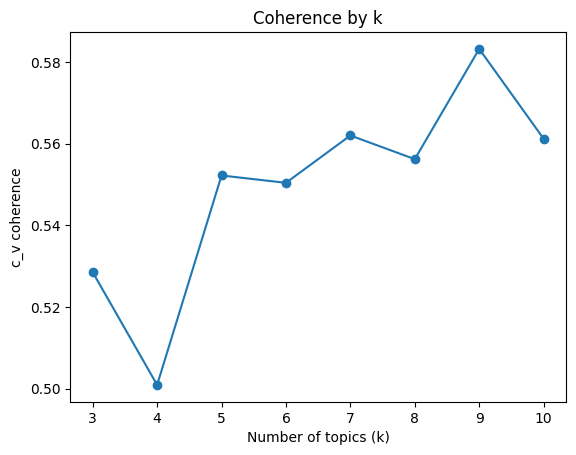

,k,c_v
0,3,0.5285
1,4,0.5009
2,5,0.5522
3,6,0.5504
4,7,0.5620
5,8,0.5562
6,9,0.5832
7,10,0.5612


In [ ]:
ks = list(range(3, 11))
rows = []
for k in ks:
    m = LdaModel(train_corpus, num_topics=k, id2word=dictionary, passes=10,
                 random_state=SEED, alpha="auto", eta="auto")
    cv = CoherenceModel(model=m, texts=train_tokens, dictionary=dictionary, coherence="c_v").get_coherence()
    rows.append({"k": k, "c_v": round(cv, 4)})
    print(k, round(cv, 4))

k_table = pd.DataFrame(rows)
plt.plot(k_table["k"], k_table["c_v"], marker="o")
plt.xlabel("Number of topics (k)"); plt.ylabel("c_v coherence"); plt.title("Coherence by k"); plt.show()
k_table

## 9. Final LDA model

In [ ]:
best_k = int(k_table.loc[k_table["c_v"].idxmax(), "k"])
print("Selected k =", best_k)

lda = LdaModel(train_corpus, num_topics=best_k, id2word=dictionary, passes=20,
               random_state=SEED, alpha="auto", eta="auto")
for i in range(best_k):
    print(f"Topic {i}:", ", ".join(w for w, _ in lda.show_topic(i, 10)))

Selected k = 9
Topic 0: bad, need, people, dress, always, dont, person, story, wanna, leave
Topic 1: good, tag, man, time, free, trust_man, want, god, tears_tears, well
Topic 2: may, god, came, world, way, see, episodes, bro, gods, everyone
Topic 3: end, back, interesting, series, someone_bring, finally_found, never, even, point, give
Topic 4: lol, let, bro, rest, would, life, also, love, see, look
Topic 5: love, story, much, two, girl, still, hard, know, man, got
Topic 6: even, people, always, story, know, water, nice, think, never, mother
Topic 7: bring_back, find, take, long, good, side, know, right, characters, shirt
Topic 8: name, real, loved, best, girls, lol, know, crying, give, cute


## 10. Evaluation (LDA)
Note: gensim's held-out perplexity is an ELBO-based estimate and is unstable on very short comments, so treat c_v as the main metric and report perplexity with that caveat.

In [ ]:
cv = CoherenceModel(model=lda, texts=train_tokens, dictionary=dictionary, coherence="c_v").get_coherence()
um = CoherenceModel(model=lda, corpus=train_corpus, dictionary=dictionary, coherence="u_mass").get_coherence()
perp = np.exp2(-lda.log_perplexity(hold_corpus))

top_words = [w for t in range(best_k) for w, _ in lda.show_topic(t, 10)]
diversity = len(set(top_words)) / len(top_words)

lda_eval = pd.DataFrame({
    "Metric": ["c_v coherence (higher better)", "u_mass coherence (closer to 0 better)",
               "Held-out perplexity (lower better)", "Topic diversity (higher better)"],
    "Value": [round(cv, 4), round(um, 4), round(perp, 2), round(diversity, 4)]})
lda_eval

,Metric,Value
0,c_v coherence (higher better),0.5864
1,u_mass coherence (closer to 0 better),-17.3648
2,Held-out perplexity (lower better),33635.8400
3,Topic diversity (higher better),0.8111


## 11. Visualization (pyLDAvis)

In [ ]:
import pyLDAvis, pyLDAvis.gensim_models as gm

vis = gm.prepare(lda, train_corpus, dictionary, mds="mmds")   # mmds avoids the PCoA complex-value error
pyLDAvis.save_html(vis, "lda_vis.html")                       # file for your report
pyLDAvis.enable_notebook()
pyLDAvis.display(vis)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 12. Assign dominant topic to each comment

In [ ]:
def dominant_topic(bow):
    dist = lda.get_document_topics(bow, minimum_probability=0)
    return max(dist, key=lambda x: x[1])[0]

train_df["lda_topic"] = [dominant_topic(b) for b in train_corpus]
hold_df["lda_topic"] = [dominant_topic(b) for b in hold_corpus]

topic_table = pd.DataFrame({
    "Topic": range(best_k),
    "Top words": [", ".join(w for w, _ in lda.show_topic(i, 8)) for i in range(best_k)],
    "Train docs": [(train_df["lda_topic"] == i).sum() for i in range(best_k)],
    "Holdout docs": [(hold_df["lda_topic"] == i).sum() for i in range(best_k)]
})
topic_table["Share of train %"] = (topic_table["Train docs"] / len(train_df) * 100).round(1)
topic_table

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,Topic,Top words,Train docs,Holdout docs,Share of train %
0,0,"bad, need, people, dress, always, dont, person...",114,12,9.8
1,1,"good, tag, man, time, free, trust_man, want, god",130,13,11.2
2,2,"may, god, came, world, way, see, episodes, bro",113,10,9.7
3,3,"end, back, interesting, series, someone_bring,...",108,13,9.3
4,4,"lol, let, bro, rest, would, life, also, love",129,17,11.1
5,5,"love, story, much, two, girl, still, hard, know",180,28,15.5
6,6,"even, people, always, story, know, water, nice...",125,15,10.8
7,7,"bring_back, find, take, long, good, side, know...",120,5,10.4
8,8,"name, real, loved, best, girls, lol, know, crying",140,16,12.1


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### Example comments per topic (used to label topics)

In [ ]:
for i in range(best_k):
    print(f"\n--- Topic {i} ---")
    for t in train_df[train_df["lda_topic"] == i]["original_text"].head(4):
        print("  -", t[:120].replace("\n", " "))


--- Topic 0 ---
  - MARK IS A GIRLS MAN IDC I LOVED HIM THE MOST
  - Hmmmm very sad and bad
  - She did come across as controlling though.. from how she spoke to how she looked at others. It may be a trauma response 
  - Did I hear my wigs,my rent,my clothes,my skincare products my transport and you still leave such a man? confused lady

--- Topic 1 ---
  - That line broke my heart
  - I knew they gon do things
  - Okay i am FULLY confused what the fuck is happening
  - They all are yelling all the time, it is tiring...

--- Topic 2 ---
  - mabutikang tao idol
  - Thats exactly what I saying!!
  - Low budget movie
  - Are these gods can fart?

--- Topic 3 ---
  - Pls someone should bring me back
  - Finaly a straight to the point shortfilm. No dragged out dialogues. 🎉🎉🎉
  - anyone else think the twin brothers name should have been moe
  - There is. I’ve watched till the end

--- Topic 4 ---
  - cool evry scene
  - This was the first time I cried over a reality tv show bc one it’s so r

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 12b. Topic labels (LDA)


In [ ]:
lda_labels = {
    0: "Clothing & Relationships",
    1: "Relationship Drama",
    2: "Gender Expression",
    3: "Channel Promos",
    4: "Relatable Emotions",
    5: "Love Stories",
    6: "Plot & Family",
    7: "Bring Me Back Requests",
    8: "Names & Experiences",
}

train_df["lda_label"] = train_df["lda_topic"].map(lda_labels).fillna(train_df["lda_topic"].apply(lambda x: f"Topic {x}"))
hold_df["lda_label"]  = hold_df["lda_topic"].map(lda_labels).fillna(hold_df["lda_topic"].apply(lambda x: f"Topic {x}"))

topic_table = topic_table.drop(columns=["Topic Category"], errors="ignore")
topic_table.insert(1, "Topic Category", topic_table["Topic"].map(lda_labels).fillna(topic_table["Topic"].apply(lambda x: f"Topic {x}")))
topic_table

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,Topic,Topic Category,Top words,Train docs,Holdout docs,Share of train %
0,0,Clothing & Relationships,"bad, need, people, dress, always, dont, person...",114,12,9.8
1,1,Trust,"good, tag, man, time, free, trust_man, want, god",130,13,11.2
2,2,Gender Expression,"may, god, came, world, way, see, episodes, bro",113,10,9.7
3,3,Channel Promos,"end, back, interesting, series, someone_bring,...",108,13,9.3
4,4,Relatable Emotions,"lol, let, bro, rest, would, life, also, love",129,17,11.1
5,5,Love Stories,"love, story, much, two, girl, still, hard, know",180,28,15.5
6,6,Plot & Family,"even, people, always, story, know, water, nice...",125,15,10.8
7,7,Bring Me Back Requests,"bring_back, find, take, long, good, side, know...",120,5,10.4
8,8,Names & Experiences,"name, real, loved, best, girls, lol, know, crying",140,16,12.1


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 13. Topic distribution by platform

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

platform                  TikTok  YouTube
lda_label                                
Bring Me Back Requests     0.114    0.066
Channel Promos             0.092    0.097
Clothing & Relationships   0.098    0.101
Gender Expression          0.091    0.121
Love Stories               0.156    0.152
Names & Experiences        0.115    0.140
Plot & Family              0.098    0.144
Relatable Emotions         0.106    0.128
Trust                      0.130    0.051


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

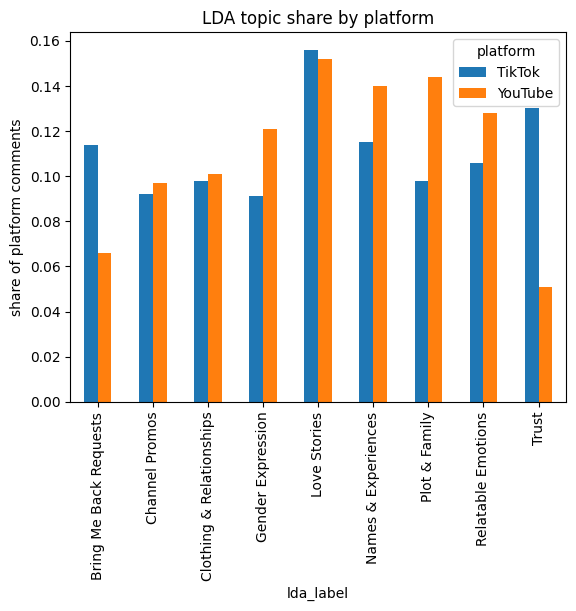

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Cosine similarity (TikTok vs YouTube topic mix): 0.9464


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
ct = pd.crosstab(train_df["lda_label"], train_df["platform"], normalize="columns").round(3)
print(ct)
ct.plot.bar(title="LDA topic share by platform"); plt.ylabel("share of platform comments"); plt.show()

# cosine similarity between the platforms' topic distributions
from numpy.linalg import norm
a, b = ct["TikTok"].values, ct["YouTube"].values
print("Cosine similarity (TikTok vs YouTube topic mix):", round(float(a @ b / (norm(a) * norm(b))), 4))

## 14. BERTopic (second model)
Uses the raw comment text and a multilingual sentence embedder, which suits short, informal, code-switched comments better than LDA. Topic `-1` holds outliers.

In [ ]:
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from umap import UMAP
from hdbscan import HDBSCAN

# BERTopic reads the RAW comments, so it also needs ordinary stopwords (the, and, this, she...)
STOP_BT = STOP | set(ENGLISH_DS) | {
    "lng", "ntin", "yan", "ito", "mo", "ni", "si", "nang", "namin", "natin", "niya",   # Tagalog fillers
    "che", "non", "per", "con", "una", "del", "sono", "come", "della", "questo",        # Italian fillers
}

def bt_tokenize(text):
    return [w for w in re.findall(r"[a-z']+", text.lower()) if w not in STOP_BT and len(w) > 2]

emb_model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")
vectorizer = CountVectorizer(tokenizer=bt_tokenize, token_pattern=None, lowercase=False)

bt = BERTopic(
    embedding_model=emb_model,
    umap_model=UMAP(n_neighbors=10, n_components=5, min_dist=0.0, metric="cosine", random_state=SEED),
    hdbscan_model=HDBSCAN(min_cluster_size=8, metric="euclidean", prediction_data=True),
    vectorizer_model=vectorizer,
    calculate_probabilities=False,
)
train_texts = train_df["original_text"].tolist()
bt_topics, _ = bt.fit_transform(train_texts)
print("Topics before reduction (excl. outliers):", len(set(bt_topics)) - (1 if -1 in bt_topics else 0))

NR_TOPICS = 10                      # merge similar topics down to about this many
bt.reduce_topics(train_texts, nr_topics=NR_TOPICS)
bt_topics = bt.topics_
train_df["bt_topic"] = bt_topics

hold_topics, _ = bt.transform(hold_df["original_text"].tolist())
hold_df["bt_topic"] = hold_topics

bt.get_topic_info()[["Topic", "Count", "Name"]]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Streaming output truncated to the last 5000 lines.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replac

### 14b. Topic labels (BERTopic)
Read the IDs and words above, then fill in `bt_labels`. Topics you leave out keep BERTopic's auto-generated name.

In [ ]:
for tid in sorted(train_df["bt_topic"].unique()):
    print(f"\n--- BT topic {tid} ---")
    for t in train_df[train_df["bt_topic"] == tid]["original_text"].head(5):
        print("  -", t[:110].replace("\n", " "))

In [ ]:
info = bt.get_topic_info()[["Topic", "Count", "Name"]]
display(info)

bt_labels = {
    -1: "Outliers",
    0: "Heartbreak & Requests",
    1: "Praise & Next Part",
    2: "Crying Over Scenes",
    3: "Faith & Gods",
    4: "Character Names",
    5: "Gender & Clothing",
    6: "Fruit Love Island",
    7: "Birthday Wishes",
    8: "Fish Jokes",
}

auto_names = dict(zip(info["Topic"], info["Name"]))
train_df["bt_label"] = train_df["bt_topic"].map(lambda t: bt_labels.get(t, auto_names.get(t, f"Topic {t}")))
hold_df["bt_label"]  = hold_df["bt_topic"].map(lambda t: bt_labels.get(t, auto_names.get(t, f"Topic {t}")))
train_df["bt_label"].value_counts()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,Topic,Count,Name
0,-1,287,-1_love_michael_bro_water
1,0,266,0_story_bring_tears_tag
2,1,209,1_good_interesting_loved_title
3,2,140,2_girl_love_cute_man
4,3,87,3_god_trust_man_protect
5,4,72,4_demarco_anime_different_time
6,5,62,5_clothing_lesbian_gay_dress
7,6,12,6_strawberry_island_milk_temptation
8,7,12,7_birthday_happy_cake_higher
9,8,12,8_fish_fishy_sea_water


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,count
bt_label,
Outliers / short generic comments,287
"Heartbreak Lines & ""Bring Me Back"" Requests",266
"Praise, Title & Next-Part Requests",209
Crying Over Scenes & Character Reactions,140
"Faith, Gods & Encouragement",87
Judging Characters & Their Names,72
"Gender Identity, Clothing & Body Image",62
Fruit Love Island Characters,12
Birthday Wishes,12


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### BERTopic evaluation (same metrics as LDA)

In [ ]:
bt_dict_tokens = [bt_tokenize(t) for t in train_texts]
bt_dict = Dictionary(bt_dict_tokens)

bt_topic_words = []
for tid in sorted(t for t in set(bt_topics) if t != -1):
    words = [w for w, _ in bt.get_topic(tid)[:10] if w in bt_dict.token2id]
    if len(words) >= 2:
        bt_topic_words.append(words)

bt_cv = CoherenceModel(topics=bt_topic_words, texts=bt_dict_tokens, dictionary=bt_dict, coherence="c_v").get_coherence()
bt_all = [w for t in bt_topic_words for w in t]
bt_div = len(set(bt_all)) / len(bt_all)
outlier_pct = round(100 * (train_df["bt_topic"] == -1).mean(), 1)

print("BERTopic topics (excl. outliers):", len(bt_topic_words))
print("c_v:", round(bt_cv, 4), "| diversity:", round(bt_div, 4), "| outliers %:", outlier_pct)
for i, w in enumerate(bt_topic_words):
    print(f"BT topic {i}:", ", ".join(w))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

BERTopic topics (excl. outliers): 9
c_v: 0.3852 | diversity: 0.9333 | outliers %: 24.8
BT topic 0: story, bring, tears, tag, came, rest, post, crying, ooo, good
BT topic 1: good, interesting, loved, title, ads, dramas, episodes, series, love, actually
BT topic 2: girl, love, cute, man, hug, did, let, felt, knows, laugh
BT topic 3: god, trust, man, protect, gods, risk, people, life, want, left
BT topic 4: demarco, anime, different, time, characters, man, jack, hes, draco, main
BT topic 5: clothing, lesbian, gay, dress, straight, dressing, wear, queer, mean, people
BT topic 6: strawberry, island, milk, temptation, did, playa, fruit, bananito, bananas, apple
BT topic 7: birthday, happy, cake, higher, celebrate, celebration, mamita, lift, candle, sweetheart
BT topic 8: fish, fishy, sea, water, going, bruv, male, brand, protein, references


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 15. Model comparison

In [ ]:
pd.DataFrame({
    "Model": ["LDA", "BERTopic"],
    "Topics": [best_k, len(bt_topic_words)],
    "c_v": [round(cv, 4), round(bt_cv, 4)],
    "Topic diversity": [round(diversity, 4), round(bt_div, 4)],
    "Outlier docs %": [0.0, outlier_pct],
    "Holdout perplexity": [round(perp, 2), "n/a"],
})

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,Model,Topics,c_v,Topic diversity,Outlier docs %,Holdout perplexity
0,LDA,9,0.5864,0.8111,0.0,33635.84
1,BERTopic,9,0.3852,0.9333,24.8,n/a


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 16. Save outputs

In [ ]:
train_df.drop(columns=["tokens"]).to_csv("topics_train.csv", index=False)
hold_df.drop(columns=["tokens"]).to_csv("topics_holdout.csv", index=False)
topic_table.to_csv("lda_topic_table.csv", index=False)
print("Saved. Reuse train_df['lda_topic'] / ['bt_topic'] for sentiment per topic and similarity measures.")

if IN_COLAB:   # Colab wipes its disk when the session ends, so download everything now
    for f in ["topics_train.csv", "topics_holdout.csv", "lda_topic_table.csv", "lda_vis.html"]:
        files.download(f)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Saved. Reuse train_df['lda_topic'] / ['bt_topic'] for sentiment per topic and similarity measures.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

...

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag